# 04 Lambda sweep, adversary rescue and operating-point selection

**Goal:** show the fairness x calibration trade-off surface of the joint model (JT), the outcome of the time-boxed adversary rescue, the committed selection rule applied once, and JT against A2, S1, S2-EG and S2-GT at the shared 10% flag rate.
Validation only (test untouched). Mean over 3 seeds.

In [1]:
import json, sys, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
RUN = ROOT / Path((ROOT / 'artifacts' / 'phase4_rundir.txt').read_text().strip())
P2 = ROOT / 'artifacts' / 'runs' / '20261101T055729Z_phase2'
FIG = RUN / 'figures'; FIG.mkdir(exist_ok=True)
pts = pd.read_csv(RUN / 'sweep_points.csv'); sel = json.loads((RUN / 'selection.json').read_text())
print('run folder:', RUN.name, '| sweep points:', len(pts), '| rule step used:', sel['step_used'])
print('rule file:', subprocess.run(['git','log','--oneline','-1','--','configs/selection_rule.yaml'],
      cwd=ROOT, capture_output=True, text=True).stdout.strip())
print('lambda-grid commit:', subprocess.run(['git','log','--oneline','-1','--','specs/09_resolved_decisions.md'],
      cwd=ROOT, capture_output=True, text=True).stdout.strip())

run folder: 20261101T065527Z_phase4 | sweep points: 26 | rule step used: base rule
rule file: f8189b2 specs: EOD-based selection rule; commit configs/selection_rule.yaml before any sweep
lambda-grid commit: 435e452 specs: revise lambda grid after phase 4 smoke (before any sweep); lambda_a via rescue protocol


## 1. Main sweep: fairness x calibration, adversary off (20 points x 3 seeds)
Grid: lambda_f in {0, 0.05, 0.1, 0.25, 0.5}, lambda_c in {0, 0.5, 1, 2}. Terms are normalised by their initial magnitude.

In [2]:
main = pts[pts.name == 'jt'].copy()
cols = ['tag','auc_roc','auc_roc_sd','auc_pr','eod','eod_sd','worst_group_ece','worst_group_ece_sd','dir','pareto']
main[cols].round(4).reset_index(drop=True)

,tag,auc_roc,auc_roc_sd,auc_pr,eod,eod_sd,worst_group_ece,worst_group_ece_sd,dir,pareto
0,f0_c0_a0,0.7465,0.0007,0.2204,0.0908,0.0101,0.3545,0.0010,0.9386,True
1,f0_c0p5_a0,0.7439,0.0003,0.2179,0.0240,0.0157,0.1419,0.0069,0.9763,True
2,f0_c1_a0,0.7421,0.0012,0.2152,0.0078,0.0042,0.0717,0.0042,0.9895,True
3,f0_c2_a0,0.7451,0.0008,0.2164,0.0425,0.0143,0.0291,0.0031,0.9653,True
4,f0p05_c0_a0,0.7426,0.0009,0.2127,0.0072,0.0064,0.3385,0.0107,0.9912,True
5,f0p05_c0p5_a0,0.7421,0.0003,0.2149,0.0079,0.0078,0.1403,0.0040,0.9853,False
6,f0p05_c1_a0,0.7424,0.0010,0.2152,0.0113,0.0132,0.0629,0.0025,0.9836,True
7,f0p05_c2_a0,0.7428,0.0009,0.2146,0.0234,0.0163,0.0189,0.0058,0.9751,True
8,f0p1_c0_a0,0.7245,0.0071,0.1816,0.0329,0.0186,0.2604,0.0773,0.9827,False
9,f0p1_c0p5_a0,0.7396,0.0017,0.2109,0.0073,0.0017,0.1408,0.0189,0.9867,True


## 2. Trade-off surface: default AUC-ROC vs EOD vs worst-group ECE

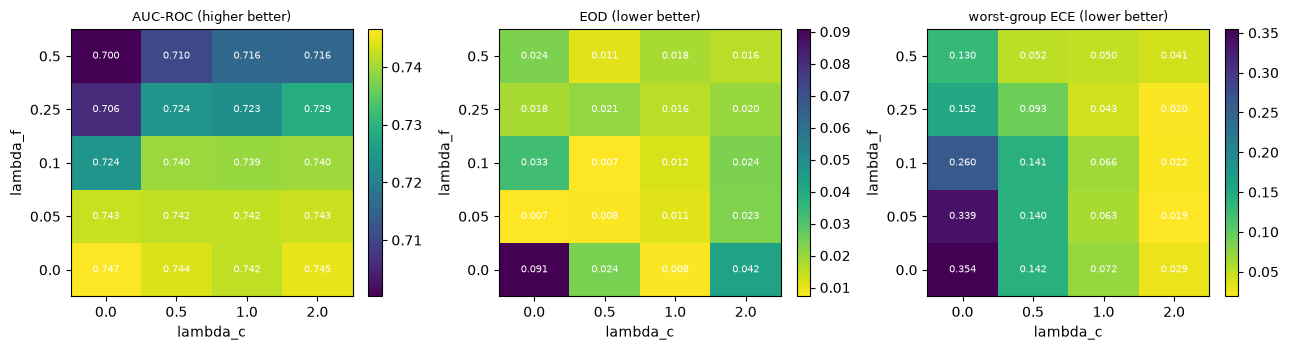

In [3]:
fs, cs = sorted(main.lambda_f.unique()), sorted(main.lambda_c.unique())
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (m, t, cm) in zip(ax, [('auc_roc','AUC-ROC (higher better)','viridis'),
                              ('eod','EOD (lower better)','viridis_r'),
                              ('worst_group_ece','worst-group ECE (lower better)','viridis_r')]):
    g = main.pivot(index='lambda_f', columns='lambda_c', values=m).loc[fs, cs]
    im = a.imshow(g.values, origin='lower', cmap=cm, aspect='auto')
    a.set_xticks(range(len(cs)), cs); a.set_yticks(range(len(fs)), fs)
    a.set_xlabel('lambda_c'); a.set_ylabel('lambda_f'); a.set_title(t, fontsize=9)
    for i in range(len(fs)):
        for j in range(len(cs)): a.text(j, i, f'{g.values[i, j]:.3f}', ha='center', va='center', color='w', fontsize=7)
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.savefig(FIG / 'surface_heatmaps.png', dpi=150); plt.show()

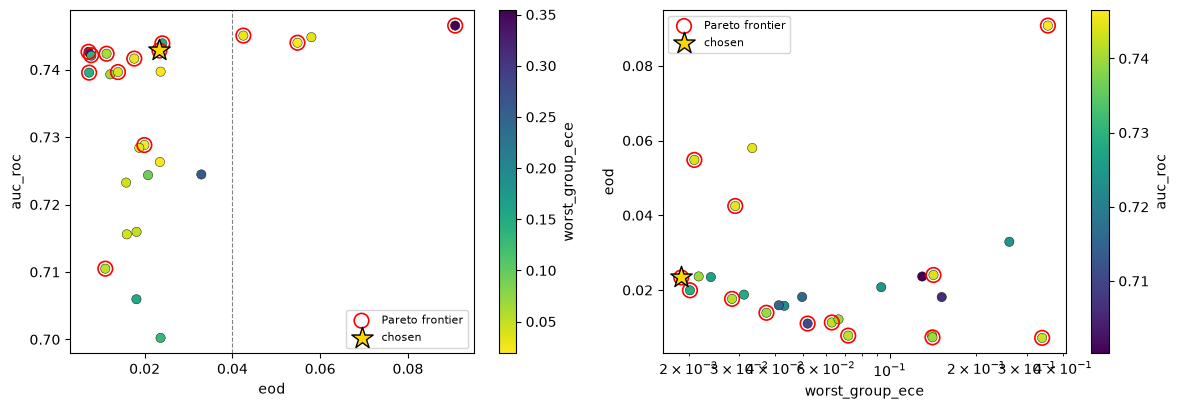

,min,max,range,typical seed sd,range / seed sd
auc_roc,0.7002,0.7465,0.0463,0.0036,12.8759
eod,0.0072,0.0908,0.0835,0.0097,8.6261
worst_group_ece,0.0189,0.3545,0.3356,0.0193,17.3698


In [4]:
allp = pts.copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (x, y, c) in zip(ax, [('eod','auc_roc','worst_group_ece'), ('worst_group_ece','eod','auc_roc')]):
    sc = a.scatter(allp[x], allp[y], c=allp[c], cmap='viridis_r' if c != 'auc_roc' else 'viridis', s=45,
                   marker='o', edgecolor='k', linewidth=0.3)
    f = allp[allp.pareto]
    a.scatter(f[x], f[y], facecolor='none', edgecolor='red', s=110, linewidth=1.2, label='Pareto frontier')
    ch = allp[(allp.tag == sel['chosen']['tag']) & (allp.name == sel['chosen']['name'])]
    a.scatter(ch[x], ch[y], marker='*', s=260, color='gold', edgecolor='k', label='chosen', zorder=5)
    a.set_xlabel(x); a.set_ylabel(y); plt.colorbar(sc, ax=a, label=c); a.legend(fontsize=8)
ax[1].set_xscale('log'); ax[0].axvline(0.04, color='grey', ls='--', lw=0.8)
plt.tight_layout(); plt.savefig(FIG / 'tradeoff_scatter.png', dpi=150); plt.show()
rng = main[['auc_roc','eod','worst_group_ece']].agg(['min','max']).T
rng['range'] = rng['max'] - rng['min']
rng['typical seed sd'] = [main.auc_roc_sd.mean(), main.eod_sd.mean(), main.worst_group_ece_sd.mean()]
rng['range / seed sd'] = rng['range'] / rng['typical seed sd']
rng.round(4)

## 3. Adversary rescue (seed 0, fairness and calibration terms off)
Success criterion fixed before the first attempt: fresh LightGBM probe on frozen z drops by at least 0.03 AUC vs the control AND default AUC-ROC loses at most 0.01. Judged by the probe, not by the adversary head's own AUC.

In [5]:
att = pd.DataFrame(json.loads((RUN / 'adversary_rescue' / 'attempts.json').read_text()))
ctrl = att[att.stage == 'control'].iloc[0]
att['probe_drop'] = ctrl.z_probe_lgbm_auc - att.z_probe_lgbm_auc
att['auc_loss'] = ctrl.auc_roc - att.auc_roc
att['works'] = (att.probe_drop >= 0.03) & (att.auc_loss <= 0.01) & (att.stage != 'control')
att['adv_mode'] = att.get('adv_mode', pd.Series(['grl'] * len(att))).fillna('grl')
att['adv_lr_mult'] = att.get('adv_lr_mult', pd.Series([1.0] * len(att))).fillna(1.0)
att[['stage','lambda_a','adv_mode','adv_lr_mult','auc_roc','z_probe_lgbm_auc','z_probe_logistic_auc',
     'probe_drop','auc_loss','adv_head_auc_best','max_train_adv_loss','works']].round(4)

,stage,lambda_a,adv_mode,adv_lr_mult,auc_roc,z_probe_lgbm_auc,z_probe_logistic_auc,probe_drop,auc_loss,adv_head_auc_best,max_train_adv_loss,works
0,control,0.00,grl,1.0,0.7471,0.7849,0.7345,0.0000,0.0000,0.5885,0.0000,False
1,a_grl_small,0.02,grl,1.0,0.7457,0.7759,0.6917,0.0089,0.0014,0.6068,0.6326,False
2,a_grl_small,0.05,grl,1.0,0.7469,0.7721,0.7193,0.0127,0.0002,0.5695,0.6350,False
3,a_grl_small,0.10,grl,1.0,0.7463,0.8053,0.7689,-0.0204,0.0008,0.6450,0.6373,False
4,a_grl_small,0.20,grl,1.0,0.7464,0.7708,0.7201,0.0141,0.0007,0.6162,0.6396,False
5,b_grl_fast_head,0.10,grl,10.0,0.7470,0.7852,0.7214,-0.0003,0.0001,0.5643,0.6372,False
6,b_grl_fast_head,0.50,grl,10.0,0.7462,0.7678,0.7120,0.0170,0.0009,0.5097,0.6427,False
7,b_grl_fast_head,1.00,grl,10.0,0.7464,0.7714,0.7293,0.0135,0.0006,0.5018,0.6429,False
8,c_confusion,0.10,confusion,1.0,0.7454,0.7809,0.6969,0.0039,0.0017,0.5994,0.7793,False
9,c_confusion,0.50,confusion,1.0,0.7429,0.7254,0.6931,0.0594,0.0042,0.5760,0.7665,True


In [6]:
# the earlier GRL failure at the original strength (artifacts/smoke/joint_stability/real_schedule.json)
old = json.loads((ROOT / 'artifacts/smoke/joint_stability/real_schedule.json').read_text())
pd.DataFrame([{'setting': k, 'min AUC-ROC after ramp': min(h['val_auc_roc'] for h in v['history'] if h['ramp'] >= 1),
               'max adversary loss': max(h.get('train_adv', 0) for h in v['history'])}
              for k, v in old.items() if k in ['(0.0, 0.0, 0.5)', '(0.0, 0.0, 1.0)']]).round(3)

,setting,min AUC-ROC after ramp,max adversary loss
0,"(0.0, 0.0, 0.5)",0.460,5.454
1,"(0.0, 0.0, 1.0)",0.459,8.157


## 4. Committed selection rule, applied once to the combined set

In [7]:
print(json.dumps({k: v for k, v in sel.items() if k not in ('chosen', 'git_hash')}, indent=1))
print('bound for worst-group ECE:', sel['ece_bound'], '| AUC-ROC floor:', round(sel['auc_floor'], 4))
pts[pts.all_ok][['name','tag','auc_roc','auc_pr','eod','worst_group_ece','dir']].round(4)

{
 "rule_file_git_tracked_hash": "configs/selection_rule.yaml (unchanged since commit f8189b2)",
 "references": {
  "a2_auc_roc": 0.7460483625577315,
  "s1_worst_group_ece": 0.01231568128402178,
  "a2_eod": 0.07629121141890151
 },
 "n_points": 26,
 "step_used": "base rule",
 "n_feasible": 1,
 "ece_bound": 0.02,
 "auc_floor": 0.7260483625577315,
 "soft_flag": false
}
bound for worst-group ECE: 0.02 | AUC-ROC floor: 0.726


,name,tag,auc_roc,auc_pr,eod,worst_group_ece,dir
7,jt,f0p05_c2_a0,0.7428,0.2146,0.0234,0.0189,0.9751


In [8]:
near = pts.assign(ece_gap=pts.worst_group_ece - sel['ece_bound']).sort_values('worst_group_ece')
near[(near.eod <= 0.04) & (near.auc_roc >= sel['auc_floor'])][
    ['name','tag','auc_roc','auc_pr','eod','worst_group_ece','ece_gap','all_ok']].round(4).head(10)

,name,tag,auc_roc,auc_pr,eod,worst_group_ece,ece_gap,all_ok
7,jt,f0p05_c2_a0,0.7428,0.2146,0.0234,0.0189,-0.0011,True
15,jt,f0p25_c2_a0,0.7288,0.1967,0.0199,0.0202,0.0002,False
11,jt,f0p1_c2_a0,0.7397,0.2105,0.0236,0.0217,0.0017,False
25,jt_conf,f0p25_c2_a1,0.7263,0.1909,0.0235,0.0239,0.0039,False
22,jt_conf,f0p05_c2_a0p5,0.7416,0.2113,0.0176,0.0283,0.0083,False
24,jt_conf,f0p25_c2_a0p5,0.7284,0.1962,0.0188,0.0312,0.0112,False
23,jt_conf,f0p05_c2_a1,0.7396,0.2082,0.0139,0.0373,0.0173,False
6,jt,f0p05_c1_a0,0.7424,0.2152,0.0113,0.0629,0.0429,False
10,jt,f0p1_c1_a0,0.7393,0.2112,0.0122,0.0664,0.0464,False
2,jt,f0_c1_a0,0.7421,0.2152,0.0078,0.0717,0.0517,False


## 5. Chosen JT point vs A2, S1, S2-EG (deployable), S2-GT (analysis only)

In [9]:
cmp = pd.read_csv(RUN / 'compare.csv')
def fmt(r, k): return f"{r[k]:.4f} [{r[k+'_lo']:.4f}, {r[k+'_hi']:.4f}]"
tbl = pd.DataFrame({'arm': cmp.arm, **{k: [fmt(r, k) for _, r in cmp.iterrows()]
                    for k in ['auc_roc','auc_pr','worst_group_ece','eod','dir','recall']}})
tbl

,arm,auc_roc,auc_pr,worst_group_ece,eod,dir,recall
0,"A2 (weighted CE, raw probabilities)","0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.3502 [0.3473, 0.3530]","0.0763 [0.0482, 0.1048]","0.9455 [0.9396, 0.9520]","0.3204 [0.3063, 0.3340]"
1,S1 (A2 + prior correction),"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0763 [0.0482, 0.1048]","0.9455 [0.9396, 0.9520]","0.3204 [0.3063, 0.3340]"
2,S2-EG (deployable),"0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0325 [0.0174, 0.0590]","0.9727 [0.9670, 0.9787]","0.3161 [0.3025, 0.3292]"
3,"S2-GT (analysis only, uses gender)","0.7460 [0.7378, 0.7541]","0.2212 [0.2110, 0.2319]","0.0123 [0.0124, 0.0154]","0.0051 [0.0042, 0.0324]","0.9871 [0.9814, 0.9932]","0.3184 [0.3039, 0.3320]"
4,JT chosen f0p05_c2_a0,"0.7428 [0.7345, 0.7508]","0.2146 [0.2047, 0.2251]","0.0189 [0.0180, 0.0200]","0.0234 [0.0141, 0.0501]","0.9751 [0.9694, 0.9808]","0.3097 [0.2954, 0.3227]"


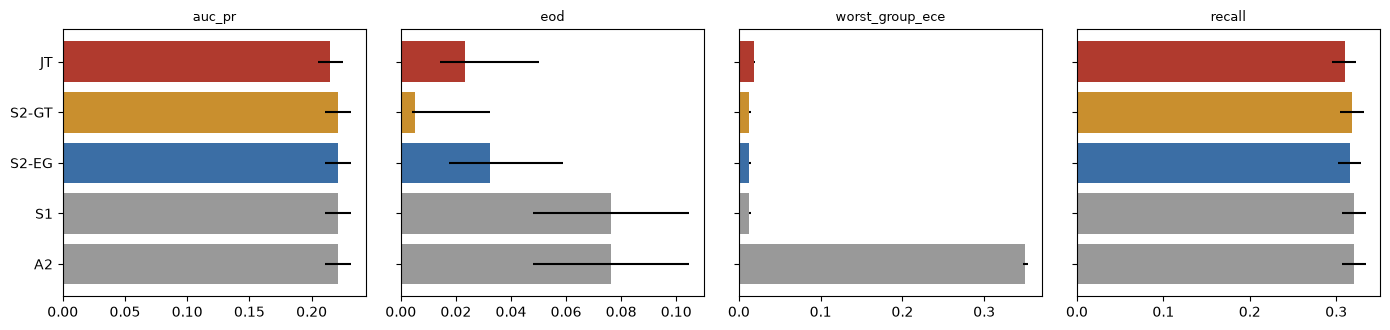

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for a, k in zip(ax, ['auc_pr','eod','worst_group_ece','recall']):
    y = cmp[k].values; e = np.clip([y - cmp[k+'_lo'], cmp[k+'_hi'] - y], 0, None)
    a.barh(range(len(cmp)), y, xerr=e, color=['#999','#999','#3b6ea5','#c98f2e','#b03a2e'])
    a.set_yticks(range(len(cmp)), [s.split(' (')[0].split(' chosen')[0] for s in cmp.arm] if k == 'auc_pr' else [])
    a.set_title(k, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'jt_vs_baselines.png', dpi=150); plt.show()

In [11]:
from src.data.tensors import load_arrays
from src.utils import load_config
from src.eval.bootstrap import bootstrap_metrics
from src.eval.metrics import METRIC_NAMES

cfg = load_config('configs/train.yaml'); val, _ = load_arrays(cfg, 'val')


def boots(base):
    out = []
    for s in [0, 1, 2]:
        d = base / f'seed_{s}'
        out.append(bootstrap_metrics(val.y, np.load(d / 'val_prob.npy'), val.a,
                                     np.load(d / 'val_flags.npy'), 1000, 0, 15))
    return np.nanmean(np.stack(out), axis=0)


jt_b = boots(RUN / sel['chosen']['name'] / sel['chosen']['tag'])
eg_b = boots(P2 / 's2_eg')
rows = []
for k in ['auc_roc', 'auc_pr', 'worst_group_ece', 'eod', 'dir', 'recall']:
    i = METRIC_NAMES.index(k)
    d = jt_b[:, i] - eg_b[:, i]
    rows.append({'metric': k, 'JT - S2-EG (mean)': d.mean(),
                 '95% CI lo': np.percentile(d, 2.5), '95% CI hi': np.percentile(d, 97.5)})
print('Paired bootstrap difference, JT chosen minus S2-EG (same resamples):')
pd.DataFrame(rows).set_index('metric').round(4)


Paired bootstrap difference, JT chosen minus S2-EG (same resamples):


,JT - S2-EG (mean),95% CI lo,95% CI hi
metric,,,
auc_roc,-0.0032,-0.0049,-0.0016
auc_pr,-0.0067,-0.0102,-0.0033
worst_group_ece,0.0052,0.0032,0.0070
eod,-0.0078,-0.0196,0.0034
dir,0.0024,-0.0003,0.0054
recall,-0.0064,-0.0132,0.0004


## 6. Ablations at the chosen settings (3 seeds) with a fresh probe on frozen z

In [12]:
ab = pd.read_csv(RUN / 'ablation.csv')
ab['AUC-ROC'] = [fmt(r, 'auc_roc') for _, r in ab.iterrows()]
ab['EOD'] = [fmt(r, 'eod') for _, r in ab.iterrows()]
ab[['arm','AUC-ROC','auc_pr','EOD','worst_group_ece','z_probe_lgbm_auc','z_probe_lgbm_sd','z_probe_logistic_auc']].round(4)

,arm,AUC-ROC,auc_pr,EOD,worst_group_ece,z_probe_lgbm_auc,z_probe_lgbm_sd,z_probe_logistic_auc
0,"control (0,0,0) = A2 + stratified sampler","0.7465 [0.7382, 0.7543]",0.2204,"0.0908 [0.0625, 0.1187]",0.3545,0.7845,0.0004,0.7300
1,"fairness only (0.05,0,0)","0.7426 [0.7341, 0.7506]",0.2127,"0.0072 [0.0052, 0.0309]",0.3385,0.7520,0.0014,0.6950
2,"calibration only (0,2,0)","0.7451 [0.7367, 0.7529]",0.2164,"0.0425 [0.0234, 0.0703]",0.0291,0.8071,0.0022,0.7679
3,"fairness + calibration (0.05,2,0) = CHOSEN","0.7428 [0.7345, 0.7508]",0.2146,"0.0234 [0.0141, 0.0501]",0.0189,0.8006,0.0035,0.7533
4,"adversary only, confusion (0,0,1)","0.7393 [0.7312, 0.7471]",0.2043,"0.1317 [0.1051, 0.1589]",0.3805,0.7158,0.0229,0.6947
5,"fairness + adversary (0.05,0,1)","0.7360 [0.7276, 0.7439]",0.2056,"0.0091 [0.0069, 0.0350]",0.3920,0.6012,0.0419,0.5764
6,"calibration + adversary (0,2,1)","0.7440 [0.7358, 0.7519]",0.2166,"0.0548 [0.0308, 0.0823]",0.0210,0.6384,0.0318,0.5876
7,"all three (0.05,2,1)","0.7396 [0.7312, 0.7473]",0.2082,"0.0139 [0.0101, 0.0368]",0.0373,0.7095,0.0276,0.6471


## 7. Test set untouched

In [13]:
log = (ROOT / 'artifacts/guard/test_access.jsonl').read_text().strip().splitlines()
print(len(log), 'guard-log entry:', json.loads(log[0]).get('purpose'))
assert len(log) == 1 and json.loads(log[0]).get('purpose') == 'leakage_probe_gender_only'

1 guard-log entry: leakage_probe_gender_only


## What this shows

Validation only, mean of 3 seeds, shared rule "flag the top 10%". The lambda grid was changed (and committed) before any sweep result existed, because lambda_f = 2 cost 0.10 to 0.2 AUC-ROC and the GRL adversary was unstable in the smoke runs.

- **The trade-off is real, not flat, but it is steep at small lambda_f.** Across the 20 main-sweep points AUC-ROC runs from 0.700 to 0.747 (seed sd about 0.004), EOD from 0.007 to 0.091 (seed sd about 0.010) and worst-group ECE from 0.019 to 0.35. The fairness term alone (lambda_f = 0.05) already takes EOD from 0.091 to 0.007 for a 0.004 AUC-ROC cost; larger lambda_f buys little more EOD and costs AUC (lambda_f = 0.5: AUC-ROC 0.70 to 0.716). The calibration term is nearly free in AUC (lambda_c = 2 alone: 0.745) and brings worst-group ECE from 0.35 to 0.029. Because the grid starts at 0.05, the cheapest part of the fairness curve is only sampled once. EOD <= 0.04 is met by 22 of 26 points, so EOD barely discriminates; worst-group ECE is the binding constraint (only 1 of 26 points is at or below 0.02).
- **Selection (committed rule, base step, no relaxation).** Exactly one of 26 points passes all constraints: lambda = (0.05, 2, 0), AUC-ROC 0.7428, AUC-PR 0.2146, EOD 0.0234, worst-group ECE 0.0189, DIR 0.975. It sits close to the ECE bound (0.0189 vs 0.02, seed sd 0.006), so it is a threshold-edge outcome. It would also have won under the first relaxation (bound 0.0246): the next candidates have a lower AUC-PR or fail EOD.
- **JT does not beat S2-EG.** On validation S2-EG (post-hoc ExponentiatedGradient on the frozen A2 representation, no gender at inference) has AUC-ROC 0.746 vs 0.743, AUC-PR 0.221 vs 0.215, worst-group ECE 0.012 vs 0.019 and recall 0.316 vs 0.310, all in S2-EG's favour. JT's only advantage is EOD (0.023 vs 0.033), and the intervals overlap widely (JT [0.014, 0.050], S2-EG [0.017, 0.059]). DIR is the same (0.975 vs 0.973). In the paired bootstrap (same resamples) JT minus S2-EG is -0.0032 AUC-ROC [-0.0049, -0.0016], -0.0067 AUC-PR [-0.0102, -0.0033], +0.0052 worst-group ECE [0.0032, 0.0070] (all significantly worse for JT), and -0.0078 EOD [-0.0196, 0.0034] (not significant). S2-GT (analysis only, uses gender, thresholds fit on validation) has the lowest EOD (0.005) and is optimistic. S1 and A2 have EOD 0.076.
- **Adversary: the spec GRL did not work; a bounded confusion loss did.** GRL with lambda_a 0.02 to 0.2 left the z-probe unchanged (0.77 to 0.81 vs 0.785 control), GRL with a 10x faster head also did not (0.77 to 0.785). The bounded confusion loss (cross-entropy to a 0.5 target, labelled a deviation from the GRL) cut the fresh LightGBM probe on frozen z to 0.725 (lambda_a 0.5) and 0.700 (1.0) at an AUC-ROC cost of 0.004 and 0.008, which meets the pre-set criterion. The probe, not the head's own AUC, is the judge.
- **The chosen point does not remove gender from z.** Its probe AUC is 0.80, slightly above the control (0.785). Fairness-only lowers the probe (0.752); calibration-only raises it (0.807); the confusion adversary lowers it most (0.716 alone, 0.60 with the fairness term, 0.64 with calibration), but with the adversary the worst-group ECE or EOD constraints fail: (0.05, 2, 1) has ECE 0.037, (0, 2, 1) has ECE 0.021 and EOD 0.055, and (0.05, 0, 1) has ECE 0.39. Seed-to-seed sd of the probe is 0.02 to 0.04 for adversary points, so these are indicative with 3 seeds.
- **Caveats.** The adversary lambda_a range was only 0.5 to 1.0 and the three (lambda_f, lambda_c) points crossed with it were picked from the main sweep frontier; no finer search was done. Selection and comparison use the same validation split, so JT's numbers are mildly optimistic, S2-EG's are not (fit on train). JT, A2 and S1 are trained with the same hyper-parameters (A2's); JT used the stratified sampler.
